[INFO] device = cuda
[INFO] hidden_dims = [512, 1024, 512]
[INFO] max_n in test = 184
[INFO] Loaded model: best_model_in5_K4_512-1024-512_testloss0.084797.pth
[INFO] Number of test samples = 200

[INFO] Mean absolute error on the test set:
  Mean x1    : 0.107139
  Mean x2    : 0.010997
  Covariance : 0.014267
[SAVED] compare_test_mean_covariance_four_gene_sci.pdf


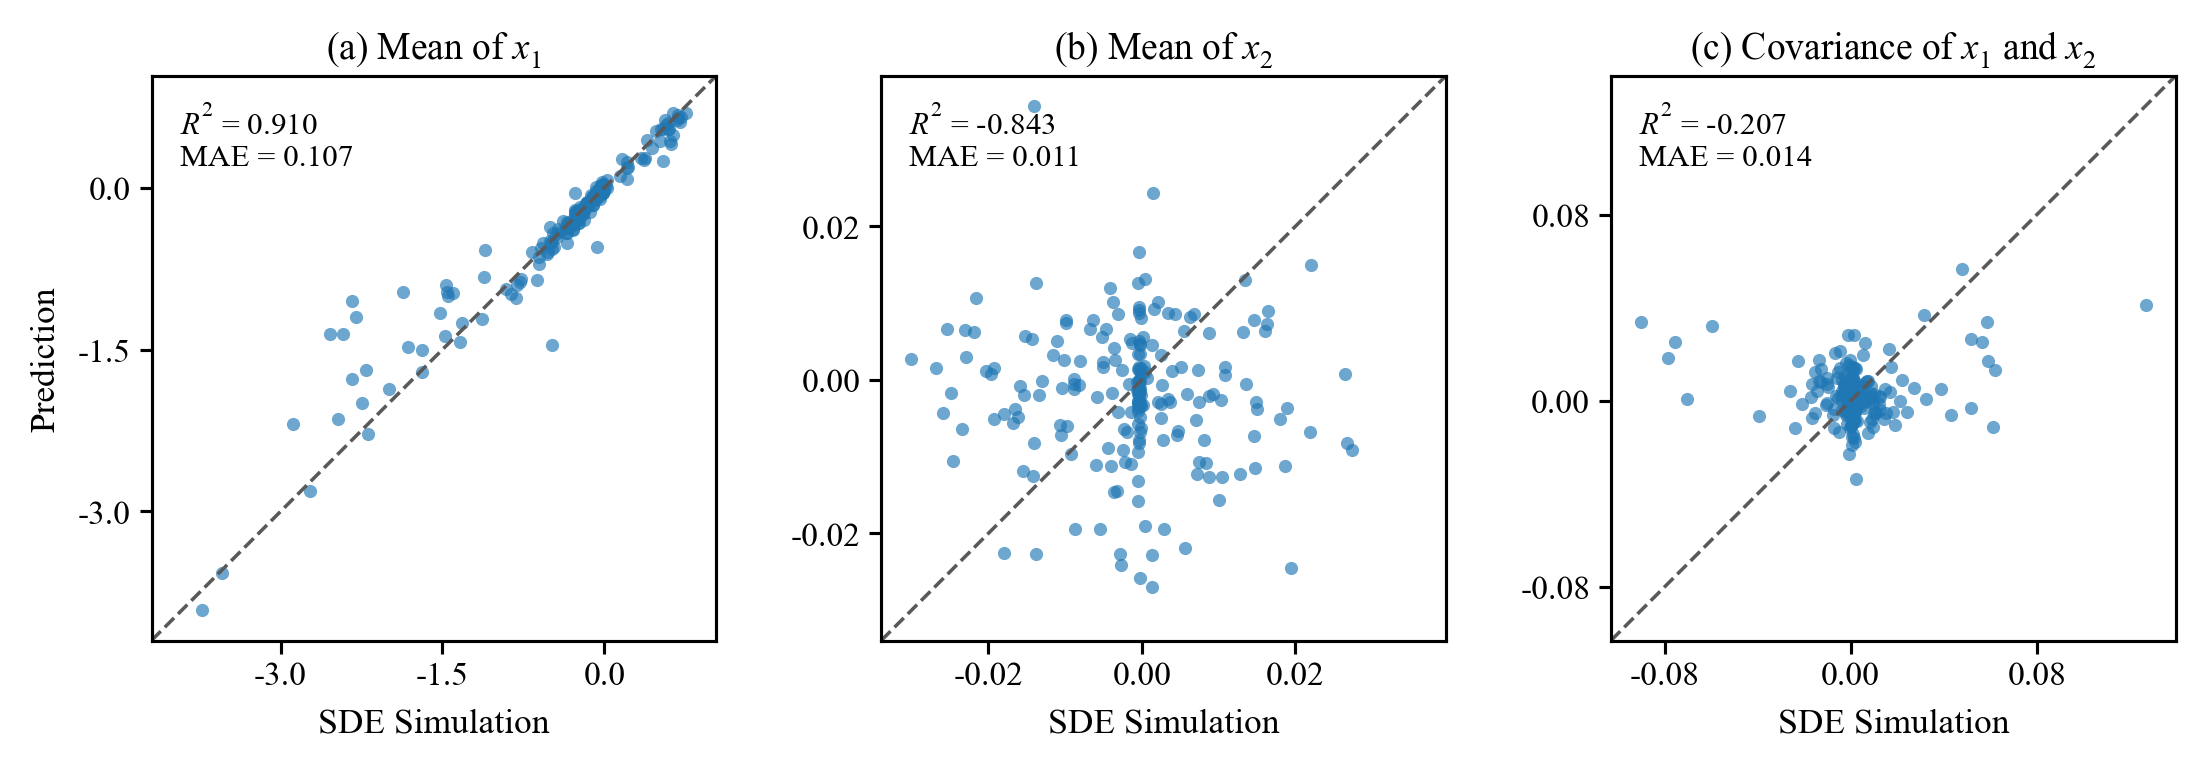

[DONE] Four-gene test-set mean/covariance comparison finished.


In [1]:
# compare_test_mean_covariance_four_gene_one_row_paper_sci.py

import os
import argparse
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from matplotlib.ticker import MaxNLocator
from torch.utils.data import Dataset, DataLoader
from scipy.io import loadmat


# ============================================================
# 0. 论文风格绘图参数
# ============================================================
def set_paper_style():
    # 英文和数字字体
    plt.rcParams["font.family"] = "Times New Roman"
    plt.rcParams["font.serif"] = ["Times New Roman"]

    # 数学字体
    plt.rcParams["mathtext.fontset"] = "custom"
    plt.rcParams["mathtext.rm"] = "Times New Roman"
    plt.rcParams["mathtext.it"] = "Times New Roman:italic"
    plt.rcParams["mathtext.bf"] = "Times New Roman:bold"

    # PDF字体嵌入，方便CorelDRAW或Illustrator编辑
    plt.rcParams["pdf.fonttype"] = 42
    plt.rcParams["ps.fonttype"] = 42

    # 字号
    plt.rcParams["font.size"] = 8.5
    plt.rcParams["axes.labelsize"] = 8.5
    plt.rcParams["axes.titlesize"] = 9
    plt.rcParams["xtick.labelsize"] = 8
    plt.rcParams["ytick.labelsize"] = 8
    plt.rcParams["legend.fontsize"] = 8

    # 坐标轴和刻度
    plt.rcParams["axes.linewidth"] = 0.75
    plt.rcParams["xtick.major.width"] = 0.75
    plt.rcParams["ytick.major.width"] = 0.75
    plt.rcParams["xtick.major.size"] = 3.0
    plt.rcParams["ytick.major.size"] = 3.0

    plt.rcParams["xtick.direction"] = "out"
    plt.rcParams["ytick.direction"] = "out"

    plt.rcParams["axes.unicode_minus"] = False

    # 分辨率
    plt.rcParams["figure.dpi"] = 300
    plt.rcParams["savefig.dpi"] = 600


# ============================================================
# 1. 四基因耦合模型对应的神经网络
# ============================================================
class MixtureOfGaussiansModel(nn.Module):
    def __init__(
        self,
        input_dim=5,
        num_components=4,
        hidden_dims=None
    ):
        super().__init__()

        if hidden_dims is None or len(hidden_dims) == 0:
            raise ValueError(
                "hidden_dims不能为空，且至少需要包含一层。"
            )

        self.input_dim = input_dim
        self.num_components = num_components
        self.hidden_dims = hidden_dims

        self.hidden_layers = nn.ModuleList()

        self.hidden_layers.append(
            nn.Linear(
                input_dim,
                hidden_dims[0]
            )
        )

        for i in range(1, len(hidden_dims)):
            self.hidden_layers.append(
                nn.Linear(
                    hidden_dims[i - 1],
                    hidden_dims[i]
                )
            )

        # 每个二维高斯分量输出6个参数
        self.output_layer = nn.Linear(
            hidden_dims[-1],
            num_components * 6
        )

    def forward(self, x):
        batch_size = x.shape[0]

        for layer in self.hidden_layers:
            x = F.relu(layer(x))

        output = self.output_layer(x)

        output = output.view(
            batch_size,
            self.num_components,
            6
        )

        # 混合权重
        weights = F.softmax(
            output[:, :, 0],
            dim=1
        )

        # 二维高斯均值
        means = output[:, :, 1:3]

        eps = 1e-6

        # 协方差矩阵参数
        s_xx = (
            F.softplus(output[:, :, 3])
            + eps
        )

        alpha = output[:, :, 4]

        rho = (
            2.0 * torch.sigmoid(alpha)
            - 1.0
        )

        rho = torch.clamp(
            rho,
            min=-1.0 + 1e-4,
            max=1.0 - 1e-4
        )

        s_yy = (
            F.softplus(output[:, :, 5])
            + eps
        )

        s_xy = rho * torch.sqrt(
            s_xx * s_yy
        )

        covariances = torch.zeros(
            batch_size,
            self.num_components,
            2,
            2,
            device=output.device,
            dtype=output.dtype
        )

        covariances[:, :, 0, 0] = s_xx
        covariances[:, :, 0, 1] = s_xy
        covariances[:, :, 1, 0] = s_xy
        covariances[:, :, 1, 1] = s_yy

        return weights, means, covariances


# ============================================================
# 2. 工具函数
# ============================================================
def mat_name(
    prefix: str,
    idx0: int,
    suffix: str = ".mat"
) -> str:
    """
    根据从0开始的索引生成MATLAB文件名。

    例如：
    idx0=0 -> ps_test{1}.mat
    idx0=1 -> ps_test{2}.mat
    """
    return f"{prefix}{{{idx0 + 1}}}{suffix}"


def find_max_n_in_dir(
    mat_dir: str,
    prefix="ps_test",
    suffix=".mat"
) -> int:
    """
    在测试集文件夹中寻找最大的密度矩阵尺寸。
    """
    max_n = 0

    for filename in os.listdir(mat_dir):
        if (
            filename.startswith(prefix)
            and filename.endswith(suffix)
        ):
            mat_path = os.path.join(
                mat_dir,
                filename
            )

            density = loadmat(
                mat_path
            ).get("density", None)

            if density is None:
                raise KeyError(
                    f"'density'未在{filename}中找到。"
                )

            if density.ndim != 2:
                raise ValueError(
                    f"{filename}中的density不是二维矩阵。"
                )

            max_n = max(
                max_n,
                int(density.shape[0])
            )

    if max_n <= 0:
        raise RuntimeError(
            f"在目录{mat_dir}中没有找到符合"
            f"{prefix}*{suffix}的文件。"
        )

    return max_n


def build_grid(
    max_n: int,
    edge: float,
    device: torch.device
):
    """
    构建训练时使用的非负二维网格。

    当edge=0.1时，网格中心为：
    0.05, 0.15, 0.25, ...
    """
    lim = max_n * edge

    centers = torch.linspace(
        edge / 2.0,
        lim - edge / 2.0,
        steps=max_n,
        dtype=torch.float32,
        device=device
    )

    # 必须使用ij，与训练代码保持一致，避免转置
    grid_x, grid_y = torch.meshgrid(
        centers,
        centers,
        indexing="ij"
    )

    return grid_x, grid_y


@torch.no_grad()
def mog_density_on_grid(
    weights,
    means,
    covariances,
    grid_x,
    grid_y,
    eps=1e-8
):
    """
    将模型输出的二维高斯混合参数转换为网格上的预测密度。
    """
    batch_size, num_components = weights.shape

    mu_x = (
        means[:, :, 0]
        .unsqueeze(-1)
        .unsqueeze(-1)
    )

    mu_y = (
        means[:, :, 1]
        .unsqueeze(-1)
        .unsqueeze(-1)
    )

    sigma_xx = (
        covariances[:, :, 0, 0]
        .unsqueeze(-1)
        .unsqueeze(-1)
    )

    sigma_xy = (
        covariances[:, :, 0, 1]
        .unsqueeze(-1)
        .unsqueeze(-1)
    )

    sigma_yy = (
        covariances[:, :, 1, 1]
        .unsqueeze(-1)
        .unsqueeze(-1)
    )

    det_sigma = (
        sigma_xx * sigma_yy
        - sigma_xy ** 2
    )

    det_sigma = torch.clamp(
        det_sigma,
        min=1e-12
    )

    inv_sigma_xx = sigma_yy / det_sigma
    inv_sigma_xy = -sigma_xy / det_sigma
    inv_sigma_yy = sigma_xx / det_sigma

    gx = (
        grid_x
        .unsqueeze(0)
        .unsqueeze(0)
    )

    gy = (
        grid_y
        .unsqueeze(0)
        .unsqueeze(0)
    )

    dx = gx - mu_x
    dy = gy - mu_y

    exponent = -0.5 * (
        inv_sigma_xx * dx ** 2
        + 2.0 * inv_sigma_xy * dx * dy
        + inv_sigma_yy * dy ** 2
    )

    gaussian = (
        1.0
        / (
            2.0
            * torch.pi
            * torch.sqrt(det_sigma)
        )
    ) * torch.exp(exponent)

    component_weights = (
        weights
        .unsqueeze(-1)
        .unsqueeze(-1)
    )

    pred_density = torch.sum(
        component_weights * gaussian,
        dim=1
    )

    pred_density = pred_density + eps

    pred_density = pred_density / pred_density.sum(
        dim=[1, 2],
        keepdim=True
    )

    return pred_density


def normalize_density(
    density,
    eps=1e-8
):
    """
    将每个密度矩阵归一化，使矩阵元素之和为1。
    """
    density = density + eps

    density = density / density.sum(
        dim=[1, 2],
        keepdim=True
    )

    return density


def mean_cov_2d(
    density,
    grid_x,
    grid_y
):
    """
    计算二维分布的：

    1. x1均值
    2. x2均值
    3. Cov(x1,x2)

    密度矩阵和网格均采用indexing='ij'。
    """
    batch_size = density.shape[0]

    gx = grid_x.unsqueeze(0).expand(
        batch_size,
        -1,
        -1
    )

    gy = grid_y.unsqueeze(0).expand(
        batch_size,
        -1,
        -1
    )

    mean_x1 = torch.sum(
        density * gx,
        dim=[1, 2]
    )

    mean_x2 = torch.sum(
        density * gy,
        dim=[1, 2]
    )

    covariance_x1_x2 = torch.sum(
        density
        * (
            gx
            - mean_x1[:, None, None]
        )
        * (
            gy
            - mean_x2[:, None, None]
        ),
        dim=[1, 2]
    )

    return (
        mean_x1,
        mean_x2,
        covariance_x1_x2
    )


def calc_r2_mae(
    true_values,
    predicted_values
):
    """
    计算R²和MAE。
    """
    true_values = np.asarray(
        true_values,
        dtype=np.float64
    )

    predicted_values = np.asarray(
        predicted_values,
        dtype=np.float64
    )

    mae = np.mean(
        np.abs(
            true_values
            - predicted_values
        )
    )

    ss_res = np.sum(
        (
            true_values
            - predicted_values
        ) ** 2
    )

    ss_tot = np.sum(
        (
            true_values
            - np.mean(true_values)
        ) ** 2
    )

    if ss_tot < 1e-12:
        r2 = np.nan
    else:
        r2 = 1.0 - ss_res / ss_tot

    return r2, mae


# ============================================================
# 3. 四基因模型测试集Dataset
# ============================================================
class TestDataset(Dataset):
    def __init__(
        self,
        csv_file,
        mat_dir,
        max_n,
        input_dim=5,
        mat_prefix="ps_test",
        mat_suffix=".mat"
    ):
        self.df = pd.read_csv(csv_file)
        self.mat_dir = mat_dir
        self.max_n = int(max_n)
        self.input_dim = int(input_dim)
        self.mat_prefix = mat_prefix
        self.mat_suffix = mat_suffix

        if self.df.shape[1] < self.input_dim:
            raise ValueError(
                f"CSV列数={self.df.shape[1]}，"
                f"小于模型输入维数input_dim={self.input_dim}。"
            )

        expected_count = len(self.df)

        actual_count = len([
            filename
            for filename in os.listdir(mat_dir)
            if (
                filename.startswith(mat_prefix)
                and filename.endswith(mat_suffix)
            )
        ])

        if actual_count != expected_count:
            raise ValueError(
                f"CSV样本数({expected_count})与"
                f"MAT文件数({actual_count})不匹配。"
            )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # 四基因模型的5个输入参数
        input_params = (
            self.df
            .iloc[idx, :self.input_dim]
            .values
            .astype(np.float32)
        )

        x = torch.tensor(
            input_params,
            dtype=torch.float32
        )

        filename = mat_name(
            self.mat_prefix,
            idx,
            self.mat_suffix
        )

        mat_path = os.path.join(
            self.mat_dir,
            filename
        )

        mat_data = loadmat(mat_path)
        density = mat_data.get(
            "density",
            None
        )

        if density is None:
            raise KeyError(
                f"'density'未在{mat_path}中找到。"
            )

        density = torch.tensor(
            density.astype(np.float32),
            dtype=torch.float32
        )

        current_n = density.shape[0]
        pad_size = self.max_n - current_n

        if pad_size > 0:
            density = F.pad(
                density,
                (0, pad_size, 0, pad_size),
                mode="constant",
                value=0.0
            )

        return x, density


# ============================================================
# 4. 横向三联散点图
# ============================================================
def scatter_three_panels_row(
    true_mean_x1,
    pred_mean_x1,
    true_mean_x2,
    pred_mean_x2,
    true_covariance,
    pred_covariance,
    out_path,
    xlabel="SDE Simulation",
    ylabel="Prediction",
    show=True
):
    """
    横向绘制三张SCI论文风格散点图：

    (a) Mean of x1
    (b) Mean of x2
    (c) Covariance of x1 and x2
    """
    set_paper_style()

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(7.4, 2.45),
        dpi=300,
        constrained_layout=True
    )

    plot_items = [
        (
            true_mean_x1,
            pred_mean_x1,
            r"(a) Mean of $x_1$"
        ),
        (
            true_mean_x2,
            pred_mean_x2,
            r"(b) Mean of $x_2$"
        ),
        (
            true_covariance,
            pred_covariance,
            r"(c) Covariance of $x_1$ and $x_2$"
        )
    ]

    for ax, (
        true_values,
        predicted_values,
        title
    ) in zip(axes, plot_items):

        true_values = np.asarray(
            true_values
        )

        predicted_values = np.asarray(
            predicted_values
        )

        # 蓝色散点
        ax.scatter(
            true_values,
            predicted_values,
            s=10,
            alpha=0.65,
            c="#1f77b4",
            linewidths=0
        )

        # 同时考虑真实值和预测值的范围
        minimum = float(
            min(
                true_values.min(),
                predicted_values.min()
            )
        )

        maximum = float(
            max(
                true_values.max(),
                predicted_values.max()
            )
        )

        margin = (
            0.06 * (maximum - minimum)
            if maximum > minimum
            else 0.05
        )

        plot_minimum = minimum - margin
        plot_maximum = maximum + margin

        # y=x参考线
        ax.plot(
            [plot_minimum, plot_maximum],
            [plot_minimum, plot_maximum],
            linestyle="--",
            linewidth=0.85,
            color="0.35"
        )

        ax.set_xlim(
            plot_minimum,
            plot_maximum
        )

        ax.set_ylim(
            plot_minimum,
            plot_maximum
        )

        # 保证y=x为45度
        ax.set_aspect(
            "equal",
            adjustable="box"
        )

        ax.set_box_aspect(1)

        ax.set_title(
            title,
            pad=4
        )

        ax.set_xlabel(
            xlabel
        )

        if ax is axes[0]:
            ax.set_ylabel(
                ylabel
            )
        else:
            ax.set_ylabel("")

        for spine in ax.spines.values():
            spine.set_linewidth(0.75)

        ax.tick_params(
            axis="both",
            which="major",
            direction="out",
            length=3,
            width=0.75,
            pad=2
        )

        ax.xaxis.set_major_locator(
            MaxNLocator(nbins=4)
        )

        ax.yaxis.set_major_locator(
            MaxNLocator(nbins=4)
        )

        # 计算R²和MAE
        r2, mae = calc_r2_mae(
            true_values,
            predicted_values
        )

        metric_text = (
            r"$R^2$ = "
            + f"{r2:.3f}\n"
            + "MAE = "
            + f"{mae:.3f}"
        )

        ax.text(
            0.05,
            0.95,
            metric_text,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=7.5
        )

    fig.savefig(
        out_path,
        format="pdf",
        bbox_inches="tight"
    )

    print(f"[SAVED] {out_path}")

    if show:
        plt.show()

    plt.close(fig)


# ============================================================
# 5. 主程序
# ============================================================
def main():
    parser = argparse.ArgumentParser()

    # 测试集CSV
    parser.add_argument(
        "--csv_test",
        type=str,
        default="ps_test.csv"
    )

    # 四基因模型测试集密度矩阵目录
    parser.add_argument(
        "--mat_test_dir",
        type=str,
        default=(
            "density_results_ps_test_"
            "n_cells=50000_python_edges=0.1"
        )
    )

    # 已训练好的四基因模型
    parser.add_argument(
        "--model_path",
        type=str,
        default=(
            "best_model_in5_K4_512-1024-512_"
            "testloss0.084797.pth"
        )
    )

    # 四基因模型有5个输入参数
    parser.add_argument(
        "--input_dim",
        type=int,
        default=5
    )

    # 模型文件为K4
    parser.add_argument(
        "--num_components",
        type=int,
        default=4
    )

    # 隐藏层结构
    parser.add_argument(
        "--hidden_dims",
        type=str,
        default="512,1024,512"
    )

    # 训练使用的网格步长
    parser.add_argument(
        "--edge",
        type=float,
        default=0.1
    )

    # 原始Xedges的最小边界
    parser.add_argument(
        "--x_min",
        type=float,
        default=-10.3
    )

    # 原始Yedges的最小边界
    parser.add_argument(
        "--y_min",
        type=float,
        default=-10.3
    )

    parser.add_argument(
        "--batch_size",
        type=int,
        default=8
    )

    parser.add_argument(
        "--num_workers",
        type=int,
        default=0
    )

    # 输出PDF名称
    parser.add_argument(
        "--out_pdf",
        type=str,
        default=(
            "compare_test_mean_covariance_"
            "four_gene_sci.pdf"
        )
    )

    # 默认显示；添加--no_show后只保存
    parser.add_argument(
        "--no_show",
        action="store_true"
    )

    # 兼容Jupyter自动注入的-f参数
    args, _ = parser.parse_known_args()

    show_figure = not args.no_show

    # ------------------------------------------------------------
    # 设备
    # ------------------------------------------------------------
    device = torch.device(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )

    print(f"[INFO] device = {device}")

    # ------------------------------------------------------------
    # 隐藏层
    # ------------------------------------------------------------
    hidden_dims = [
        int(value)
        for value in args.hidden_dims.split(",")
        if value.strip()
    ]

    print(
        f"[INFO] hidden_dims = "
        f"{hidden_dims}"
    )

    # ------------------------------------------------------------
    # 测试集中最大密度矩阵尺寸
    # ------------------------------------------------------------
    max_n = find_max_n_in_dir(
        mat_dir=args.mat_test_dir,
        prefix="ps_test",
        suffix=".mat"
    )

    print(
        f"[INFO] max_n in test = "
        f"{max_n}"
    )

    # ------------------------------------------------------------
    # 建立训练坐标系中的非负网格
    # ------------------------------------------------------------
    grid_x, grid_y = build_grid(
        max_n=max_n,
        edge=args.edge,
        device=device
    )

    # ------------------------------------------------------------
    # 创建并加载模型
    # ------------------------------------------------------------
    model = MixtureOfGaussiansModel(
        input_dim=args.input_dim,
        num_components=args.num_components,
        hidden_dims=hidden_dims
    ).to(device)

    state_dict = torch.load(
        args.model_path,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(
        state_dict
    )

    model.eval()

    print(
        f"[INFO] Loaded model: "
        f"{args.model_path}"
    )

    # ------------------------------------------------------------
    # 加载测试集
    # ------------------------------------------------------------
    test_dataset = TestDataset(
        csv_file=args.csv_test,
        mat_dir=args.mat_test_dir,
        max_n=max_n,
        input_dim=args.input_dim,
        mat_prefix="ps_test",
        mat_suffix=".mat"
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=args.batch_size,
        shuffle=False,
        num_workers=args.num_workers,
        pin_memory=torch.cuda.is_available()
    )

    print(
        f"[INFO] Number of test samples = "
        f"{len(test_dataset)}"
    )

    # ------------------------------------------------------------
    # 保存真实值和预测值
    # ------------------------------------------------------------
    true_mean_x1_list = []
    true_mean_x2_list = []
    true_covariance_list = []

    pred_mean_x1_list = []
    pred_mean_x2_list = []
    pred_covariance_list = []

    # ------------------------------------------------------------
    # 测试集预测
    # ------------------------------------------------------------
    with torch.no_grad():
        for input_batch, density_batch in test_loader:
            input_batch = input_batch.to(device)
            density_batch = density_batch.to(device)

            # 真实密度归一化
            true_density = normalize_density(
                density_batch
            )

            # 模型输出参数
            (
                weights,
                means,
                covariances
            ) = model(input_batch)

            # 在非负训练网格上构造预测密度
            pred_density = mog_density_on_grid(
                weights,
                means,
                covariances,
                grid_x,
                grid_y
            )

            # 真实密度的均值和协方差
            (
                true_mean_x1,
                true_mean_x2,
                true_covariance
            ) = mean_cov_2d(
                true_density,
                grid_x,
                grid_y
            )

            # 预测密度的均值和协方差
            (
                pred_mean_x1,
                pred_mean_x2,
                pred_covariance
            ) = mean_cov_2d(
                pred_density,
                grid_x,
                grid_y
            )

            # 将均值从非负训练坐标平移回原始坐标
            true_mean_x1 = (
                true_mean_x1
                + args.x_min
            )

            pred_mean_x1 = (
                pred_mean_x1
                + args.x_min
            )

            true_mean_x2 = (
                true_mean_x2
                + args.y_min
            )

            pred_mean_x2 = (
                pred_mean_x2
                + args.y_min
            )

            # 协方差不受常数平移影响，因此无需修改

            true_mean_x1_list.append(
                true_mean_x1.cpu().numpy()
            )

            true_mean_x2_list.append(
                true_mean_x2.cpu().numpy()
            )

            true_covariance_list.append(
                true_covariance.cpu().numpy()
            )

            pred_mean_x1_list.append(
                pred_mean_x1.cpu().numpy()
            )

            pred_mean_x2_list.append(
                pred_mean_x2.cpu().numpy()
            )

            pred_covariance_list.append(
                pred_covariance.cpu().numpy()
            )

    # ------------------------------------------------------------
    # 拼接所有batch
    # ------------------------------------------------------------
    true_mean_x1 = np.concatenate(
        true_mean_x1_list
    )

    true_mean_x2 = np.concatenate(
        true_mean_x2_list
    )

    true_covariance = np.concatenate(
        true_covariance_list
    )

    pred_mean_x1 = np.concatenate(
        pred_mean_x1_list
    )

    pred_mean_x2 = np.concatenate(
        pred_mean_x2_list
    )

    pred_covariance = np.concatenate(
        pred_covariance_list
    )

    # ------------------------------------------------------------
    # 输出误差
    # ------------------------------------------------------------
    print(
        "\n[INFO] Mean absolute error "
        "on the test set:"
    )

    print(
        f"  Mean x1    : "
        f"{np.mean(np.abs(true_mean_x1 - pred_mean_x1)):.6f}"
    )

    print(
        f"  Mean x2    : "
        f"{np.mean(np.abs(true_mean_x2 - pred_mean_x2)):.6f}"
    )

    print(
        f"  Covariance : "
        f"{np.mean(np.abs(true_covariance - pred_covariance)):.6f}"
    )

    # ------------------------------------------------------------
    # 绘制三联图
    # ------------------------------------------------------------
    scatter_three_panels_row(
        true_mean_x1=true_mean_x1,
        pred_mean_x1=pred_mean_x1,
        true_mean_x2=true_mean_x2,
        pred_mean_x2=pred_mean_x2,
        true_covariance=true_covariance,
        pred_covariance=pred_covariance,
        out_path=args.out_pdf,
        xlabel="SDE Simulation",
        ylabel="Prediction",
        show=show_figure
    )

    print(
        "[DONE] Four-gene test-set "
        "mean/covariance comparison finished."
    )


if __name__ == "__main__":
    main()